# Telco Customer Churn Prediction


## Problem Statement
A telecom company wants to identify customers who may leave the company. If these customers are found early, the company can contact them and provide suitable retention offers. In this project, I use the Telco Customer Churn dataset to predict whether a customer is likely to churn or stay.

In [1]:
%pip install pandas matplotlib seaborn sklearn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

## 1. Loading the dataset

In [2]:
import pandas as pd

file_path = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
df = pd.read_csv(file_path)

print('Dataset shape:', df.shape)
df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


The dataset contains customer details such as tenure, contract, internet service, payment method and monthly charges. The `Churn` column is the output that we want to predict.

## 2. Understanding the data

In [3]:
print('Column names:')
print(df.columns.tolist())

print('\nData types:')
print(df.dtypes)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [4]:
print('Missing values:')
print(df.isnull().sum())

print('Duplicate rows:', df.duplicated().sum())

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate rows: 0


## 3. Cleaning the data

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.drop('customerID', axis=1)
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print(df.head())

   gender SeniorCitizen Partner Dependents  tenure PhoneService  \
0  Female             0     Yes         No       1           No   
1    Male             0      No         No      34          Yes   
2    Male             0      No         No       2          Yes   
3    Male             0      No         No      45           No   
4  Female             0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
0               No          No          No              No  Month-to-month   
1              Yes          No        

`customerID` is only an identifier, so I removed it. `TotalCharges` was converted to a numeric column. Finally, the target was changed to 0 and 1, where 1 means churn.

## 4. Churn distribution

Customers who stayed: 5174
Customers who churned: 1869


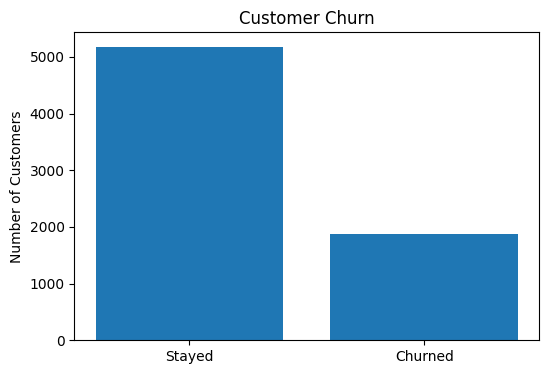

In [6]:
import matplotlib.pyplot as plt

print('Customers who stayed:', (df['Churn'] == 0).sum())
print('Customers who churned:', (df['Churn'] == 1).sum())

counts = df['Churn'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(['Stayed','Churned'], [counts.get(0,0), counts.get(1,0)])
plt.title('Customer Churn')
plt.ylabel('Number of Customers')
plt.show()

More customers stayed than churned. Because the classes are not perfectly balanced, I will use precision, recall and F1 score along with accuracy.

## 5. Selecting input and output

In [7]:
X = df.drop('Churn', axis=1)
y = df['Churn']

categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
numeric_columns = X.select_dtypes(include=['number']).columns.tolist()

print('Categorical columns:')
print(categorical_columns)
print('\nNumerical columns:')
print(numeric_columns)

Categorical columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical columns:
['tenure', 'MonthlyCharges', 'TotalCharges']


Customer information such as tenure, contract type, monthly charges, internet service and payment method can influence churn, so these are used as input features.

## 6. Splitting the dataset

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print('Training data:', X_train.shape)
print('Testing data:', X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


I used 80% of the data for training and 20% for testing. The test data is used to check how the model works on records it has not seen during training.

## 7. Preparing the data

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_process = Pipeline([
    ('fill_missing', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])

categorical_process = Pipeline([
    ('fill_missing', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numbers', numeric_process, numeric_columns),
    ('categories', categorical_process, categorical_columns)
])

Numerical values are scaled and categorical values are converted into numerical columns using one-hot encoding. Missing values are handled inside the preprocessing pipeline.

## 8. Building the model

In [10]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42))
])

model.fit(X_train, y_train)
print('Model trained successfully.')

Model trained successfully.


I selected Logistic Regression because churn is a binary classification problem. It also gives a probability, which is useful for deciding which customers need attention.

## 9. Making predictions

In [11]:
y_probability = model.predict_proba(X_test)[:, 1]
y_prediction = (y_probability >= 0.50).astype(int)

result = X_test.copy()
result['Churn Probability'] = y_probability.round(3)
result['Actual Churn'] = y_test.values
result['Prediction'] = y_prediction
result['Result'] = result['Prediction'].map({0:'Likely to Stay', 1:'Likely to Churn'})

result[['Churn Probability','Actual Churn','Result']].head(10)

,Churn Probability,Actual Churn,Result
437,0.115,0,Likely to Stay
2280,0.852,0,Likely to Churn
2235,0.146,0,Likely to Stay
4460,0.661,0,Likely to Churn
3761,0.060,0,Likely to Stay
5748,0.805,0,Likely to Churn
3568,0.698,0,Likely to Churn
2976,0.293,0,Likely to Stay
5928,0.009,0,Likely to Stay
1639,0.652,1,Likely to Churn


A probability of 0.50 or higher is treated as likely to churn. A lower probability is treated as likely to stay.

## 10. Model evaluation

In [12]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

accuracy = accuracy_score(y_test, y_prediction)
precision = precision_score(y_test, y_prediction)
recall = recall_score(y_test, y_prediction)
f1 = f1_score(y_test, y_prediction)
auc = roc_auc_score(y_test, y_probability)

print('Accuracy :', round(accuracy,3))
print('Precision:', round(precision,3))
print('Recall   :', round(recall,3))
print('F1 Score :', round(f1,3))
print('ROC-AUC  :', round(auc,3))

Accuracy : 0.737
Precision: 0.503
Recall   : 0.783
F1 Score : 0.613
ROC-AUC  : 0.841


Recall is especially important here because the company wants to find customers who are actually going to leave. Precision is also important because retention offers cost money.

## 11. Confusion Matrix

Churn customers correctly identified (TP): 293
Non-churn customers correctly identified (TN): 746
Non-churn customers wrongly flagged (FP): 289
Churn customers missed (FN): 81


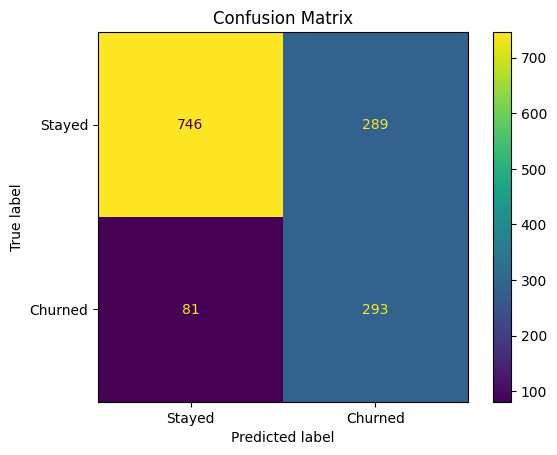

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_prediction)
tn, fp, fn, tp = cm.ravel()

print('Churn customers correctly identified (TP):', tp)
print('Non-churn customers correctly identified (TN):', tn)
print('Non-churn customers wrongly flagged (FP):', fp)
print('Churn customers missed (FN):', fn)

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Stayed','Churned']).plot()
plt.title('Confusion Matrix')
plt.show()

**True Positive:** the customer churned and the model found it.  
**True Negative:** the customer stayed and the model correctly predicted stay.  
**False Positive:** the customer stayed but was flagged as churn. The company may spend money unnecessarily.  
**False Negative:** the customer churned but the model missed them. This can be more costly because the company loses the chance to retain the customer.

## 12. Classification report

In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_prediction, target_names=['Stayed','Churned']))

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## 13. ROC Curve

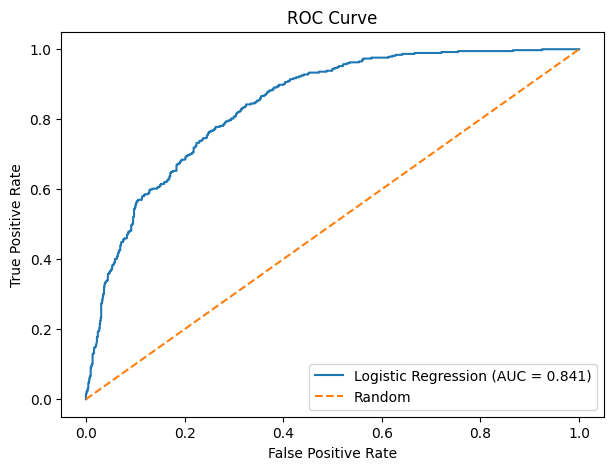

In [15]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0,1], [0,1], '--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 14. Predicting an unseen customer

In [16]:
import numpy as np

def predict_customer(customer_data, threshold=0.50):
    customer = pd.DataFrame(customer_data)
    probability = model.predict_proba(customer)[:,1]
    prediction = (probability >= threshold).astype(int)
    output = customer.copy()
    output['Churn Probability'] = probability.round(3)
    output['Prediction'] = np.where(prediction == 1, 'Likely to Churn', 'Likely to Stay')
    return output

In [17]:
new_customer = X_test.iloc[[0]].to_dict(orient='records')
predict_customer(new_customer)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn Probability,Prediction
0,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,...,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.2,0.115,Likely to Stay


## 15. Business interpretation

From a business point of view, I would generally be more concerned about a **False Negative** than a **False Positive**. A false negative means a customer who is actually going to leave was not identified. The company may lose that customer and future revenue. A false positive can also cost money because the company may give a retention offer to someone who would have stayed anyway. The company should therefore balance recall with the cost of retention offers.

## 16. One improvement

One improvement would be to **tune the prediction threshold** instead of always using 0.50. If missing a customer is more expensive than contacting an extra customer, the company can use a lower threshold to find more possible churn customers. Another option is to compare this model with Random Forest or Gradient Boosting using cross-validation.

## 17. Final conclusion

In this project, I used the Telco Customer Churn dataset to build a machine learning model for predicting customer churn. I cleaned the data, prepared numerical and categorical features, trained a Logistic Regression model and generated churn probabilities. I evaluated the model using accuracy, precision, recall, F1 score, ROC-AUC and a confusion matrix. The company can use the predicted probabilities to focus retention campaigns on customers who have a higher chance of leaving.

## Dataset Source

Telco Customer Churn — Kaggle  
https://www.kaggle.com/datasets/blastchar/telco-customer-churn